In [1]:
%%html
<span class="cosi-notebook-theme" style="display:none;"></span>

<style>
/* =====================================================
   JupyterLab Markdown Heading Theme
   Original design restored — H1 to H4
   ===================================================== */

/* H1 — Deep Blue → Bright Blue Gradient */
.jp-Notebook:has(.cosi-notebook-theme) .jp-RenderedMarkdown h1 {
    background: linear-gradient(90deg, #1e3a8a, #3b82f6);
    color: #ffffff;
    padding: 20px 25px;
    border-radius: 8px;
    margin-top: 30px;
    margin-bottom: 18px;
    font-weight: 700;
}

/* H2 — Light Blue Background + Blue Left Border */
.jp-Notebook:has(.cosi-notebook-theme) .jp-RenderedMarkdown h2 {
    background-color: #eff6ff;
    color: #1e40af;
    border-left: 6px solid #2563eb;
    padding: 12px 16px;
    border-radius: 5px;
    margin-top: 24px;
    margin-bottom: 14px;
    font-weight: 650;
}

/* H3 — Teal Text + Bottom Border */
.jp-Notebook:has(.cosi-notebook-theme) .jp-RenderedMarkdown h3 {
    color: #0f766e;
    border-bottom: 2px solid #99f6e4;
    padding: 7px 4px;
    margin-top: 20px;
    margin-bottom: 12px;
    font-weight: 600;
}

/* H4 — Slate Text + Subtle Left Border */
.jp-Notebook:has(.cosi-notebook-theme) .jp-RenderedMarkdown h4 {
    color: #475569;
    border-left: 3px solid #94a3b8;
    padding: 5px 10px;
    margin-top: 16px;
    margin-bottom: 10px;
    font-weight: 600;
}
</style>


# Imports and Preparation

In [2]:
# Standard library
import logging
from datetime import date
from pathlib import Path

# Third-party packages
import astropy.units as u
from astropy.coordinates import SkyCoord

# Photozpy
from photozpy import (
    Artifacts,
    Combine,
    HeaderCorrection,
    ImageCollectionGroup,
    ImageReviewer,
    PlateSolving,
    Reduction,
    Registration,
)
from photozpy.collections.image_collection_helpers import (
    refresh_image_collection_group,
)
from photozpy.photometry.fwhm import FWHM
from photozpy.photometry.photometry import Photometry
from photozpy.photometry.regions import (
    PhotometryRegionCollection,
    PhotometryRegions,
)
from photozpy.sources import ObservationField, SourceInfo, Sources
from photozpy.standard_stars import StandardStarCatalog
from photozpy.telescope import SARA_RM


# Logging configuration
logging.basicConfig(
    level=logging.INFO,
    format="%(levelname)s: %(message)s",
)
logging.getLogger("photozpy").setLevel(logging.INFO)

## Check the telescope

### Check CCD

In [3]:
telescope = SARA_RM

In [4]:

telescope.print_ccd_summary()

╒════════════════════╤════════════════════╕
│ field              │ value              │
╞════════════════════╪════════════════════╡
│ name               │ RM Andor Ikon-L    │
├────────────────────┼────────────────────┤
│ gain               │ 1.0 electron / adu │
├────────────────────┼────────────────────┤
│ rdnoise            │ 6.3 electron / pix │
├────────────────────┼────────────────────┤
│ valid_from         │ 2016-01-01         │
├────────────────────┼────────────────────┤
│ valid_to           │ 9999-12-31         │
├────────────────────┼────────────────────┤
│ native_pixel_scale │ 0.34 arcsec / pix  │
├────────────────────┼────────────────────┤
│ nx                 │                    │
├────────────────────┼────────────────────┤
│ ny                 │                    │
├────────────────────┼────────────────────┤
│ saturation         │                    │
├────────────────────┼────────────────────┤
│ full_well          │                    │
├────────────────────┼──────────

### Check Filters

In [5]:
telescope.print_filterset_summary()

╒═════════════════════════╤═══════════════════════════════════════════════════════════╕
│ Standard Filter Names   │ Alias                                                     │
╞═════════════════════════╪═══════════════════════════════════════════════════════════╡
│ SDSS_u'                 │ ("Sloan u'2", 'SDSS u', "Sloan_u'2", 'SDSS_u', 'SDSS_up') │
├─────────────────────────┼───────────────────────────────────────────────────────────┤
│ SDSS_g'                 │ ("Sloan g'2", 'SDSS g', "Sloan_g'2", 'SDSS_g', 'SDSS_gp') │
├─────────────────────────┼───────────────────────────────────────────────────────────┤
│ SDSS_r'                 │ ("Sloan r'2", 'SDSS r', "Sloan_r'2", 'SDSS_r', 'SDSS_rp') │
├─────────────────────────┼───────────────────────────────────────────────────────────┤
│ SDSS_i'                 │ ("Sloan i'2", 'SDSS i', "Sloan_i'2", 'SDSS_i', 'SDSS_ip') │
├─────────────────────────┼───────────────────────────────────────────────────────────┤
│ SDSS_z'                 │ ("Sl

## Define Sources Observed

### First, let's define observation fields

In [6]:
# _field = ObservationField(
#     field_name="",
#     telescope=telescope,
#     nominal_pointing=SkyCoord(
#         ra="",
#         dec="",
#         frame="icrs",
#         unit=(u.hourangle, u.deg),
#     ),
#     file_pattern="",
# )

In [7]:
GB6_field = ObservationField(
    field_name="GB6",
    telescope=telescope,
    nominal_pointing=SkyCoord(
        ra="10:47:47.52",
        dec="+72:38:13.0",
        frame="icrs",
        unit=(u.hourangle, u.deg),
    ),
    file_pattern="GB6",
)

In [8]:
TXS_field = ObservationField(
    field_name="TXS",
    telescope=telescope,
    nominal_pointing=SkyCoord(
        ra="13:31:33.44",
        dec="+17:12:50.60",
        frame="icrs",
        unit=(u.hourangle, u.deg),
    ),
    file_pattern="TXS",
)

In [9]:
PG_field = ObservationField(
    field_name="PG",
    telescope=telescope,
    nominal_pointing=SkyCoord(
        ra="16:35:32",
        dec="+09:47:50",
        frame="icrs",
        unit=(u.hourangle, u.deg),
    ),
    file_pattern="PG",
)

In [10]:
RX_field = ObservationField(
    field_name="RX",
    telescope=telescope,
    nominal_pointing=SkyCoord(
        ra="18:09:25.45",
        dec="+20:41:30.90",
        frame="icrs",
        unit=(u.hourangle, u.deg),
    ),
    file_pattern="RX",
)

In [11]:
B3_field = ObservationField(
    field_name="B3",
    telescope=telescope,
    nominal_pointing=SkyCoord(
        ra="10:32:40.72",
        dec="+37:38:26.75",
        frame="icrs",
        unit=(u.hourangle, u.deg),
    ),
    file_pattern="B2",
)

In [12]:
standard_star_field = PG_field

In [13]:
fields = (GB6_field, TXS_field, PG_field, RX_field, B3_field)

### Next, let's define sources in each observation field

In [14]:
#  = SourceInfo(
#     source_name="",
#     source_role="science",
#     source_coordinate=SkyCoord(
#         ra="",
#         dec="",
#         frame="icrs",
#         unit=(u.hourangle, u.deg),
#     ),
#     observation_field=,
# )

In [15]:
TXS_1329 = SourceInfo(
    source_name="TXS 1329+174",
    source_role="science",
    source_coordinate=SkyCoord(
        ra="13:31:33.44",
        dec="+17:12:50.60",
        frame="icrs",
        unit=(u.hourangle, u.deg),
    ),
    observation_field=TXS_field,
)

In [16]:
RX_J1809 = SourceInfo(
    source_name="RX J1809.3+2041",
    source_role="science",
    source_coordinate=SkyCoord(
        ra="18:09:25.45",
        dec="+20:41:30.90",
        frame="icrs",
        unit=(u.hourangle, u.deg),
    ),
    observation_field=RX_field,
)

In [17]:
GB6_J1047 = SourceInfo(
    source_name="GB6 J1047+7238",
    source_role="science",
    source_coordinate=SkyCoord(
        ra="10:47:47.52",
        dec="+72:38:13.0",
        frame="icrs",
        unit=(u.hourangle, u.deg),
    ),
    observation_field=GB6_field,
)

In [18]:
B3_1029 = SourceInfo(
    source_name="B3 1029+378",
    source_role="science",
    source_coordinate=SkyCoord(
        ra="10:32:40.72",
        dec="+37:38:26.75",
        frame="icrs",
        unit=(u.hourangle, u.deg),
    ),
    observation_field=B3_field,
)

<!-- NOTE -->
<div style="background-color:#e7f3ff; border-left:4px solid #2196f3; padding:12px 16px; border-radius:4px; margin:12px 0;">
  <strong>📝 Note: How about standard stars?</strong>
  <p>There is no need to create standard sources yet. They will be created automatically after standard searching.</p>
</div>

In [19]:
sources = Sources(TXS_1329, RX_J1809, GB6_J1047, B3_1029)

In [20]:
sources[0]

Sources(
  source_name='TXS 1329+174',
  coordinates (ICRS): 13:31:33.44 +17:12:50.60,
  magnitudes: instrumental=undefined, reference=undefined, calibrated=undefined
)

# Create Image File Collection 

In [21]:
data_root_dir = Path("")

raw_image_collection = ImageCollectionGroup(
    directories=data_root_dir,
)

In [22]:
# For restart analysis

analysis_dir = data_root_dir / "analysis"

analysis_images = ImageCollectionGroup(
    directories=analysis_dir,
)

# Examine Image Quality

In [43]:
# Get the image list
review_images = [
    Path(filename)
    for collection in raw_image_collection
    for filename in collection.files_filtered(include_path=True)
]

In [44]:
# Start a reviewer
reviewer = ImageReviewer(
    images=review_images,
    rejected_dir=data_root_dir / "rejected",
    isolated=True,
)

rejected_images = reviewer.run()

print(f"Reviewed: {reviewer.index}/{len(review_images)}")
print(f"Rejected: {len(rejected_images)}")

# Refresh the raw collection after rejected files have been moved.
refresh_image_collection_group(raw_image_collection)

Reviewed: 291/291
Rejected: 2


# Calibration

## Update Fits Headers

In [45]:
analysis_dir = data_root_dir / "analysis"

headers = HeaderCorrection(
    image_collection=raw_image_collection,
    observation_fields=fields,
    save_location=analysis_dir,
    overwrite=False,
)

In [46]:
# Standardize IMTYPE; add FIELD for light frames; update GAIN, RDNOISE,
# and BUNIT; compute MJD-OBS using DATE-OBS and TIMESYS.
# Fill missing RA/DEC from nominal field pointing; preserve OBJECT.
# Save the working copies in analysis/.
analysis_images: ImageCollectionGroup = headers.correct_headers_by_filename(overwrite=True)

Updating FITS headers:   0%|          | 0/289 [00:00<?, ?file/s]

In [49]:
# 本晚 FILTER header 为 '---'，改用文件名中手动记录的 griz。
# 例如 B2_1029_g_001.fits → SDSS_g'
#      Flat_z_010.fits    → SDSS_z'
filename_filter_mapping = {
    "_g_": "SDSS_g'",
    "_r_": "SDSS_r'",
    "_i_": "SDSS_i'",
    "_z_": "SDSS_z'",
}

analysis_images: ImageCollectionGroup = headers.correct_filter_headers(
    overwrite=True,
    from_file_name=True,
    filter_mapping=filename_filter_mapping,
)

Updating FITS headers:   0%|          | 0/289 [00:00<?, ?file/s]

In [48]:
# # Standardize FILTER names for Flat and Light frames using telescope aliases.
# # Update the working copies in analysis/; leave other frames unchanged.
# analysis_images: ImageCollectionGroup = headers.correct_filter_headers(overwrite=True)

## Bias Correction

In [51]:
# Build the master bias and return the updated image collection.

combiner: Combine = Combine(
    image_collection=analysis_images,
    telescope=telescope,
)

analysis_images: ImageCollectionGroup = combiner.combine_bias_or_dark(
    image_type="Bias",
)

INFO: Bias
----------------------------------------------------------------
Combining 30 Bias frames → Master_Bias.fits
Input files:
  Bias_001.fits, Bias_002.fits, Bias_003.fits, Bias_004.fits, Bias_005.fits,
  Bias_006.fits, Bias_007.fits, Bias_008.fits, Bias_009.fits, Bias_010.fits,
  Bias_011.fits, Bias_012.fits, Bias_013.fits, Bias_014.fits, Bias_015.fits,
  Bias_016.fits, Bias_017.fits, Bias_018.fits, Bias_019.fits, Bias_020.fits,
  Bias_021.fits, Bias_022.fits, Bias_023.fits, Bias_024.fits, Bias_025.fits,
  Bias_026.fits, Bias_027.fits, Bias_028.fits, Bias_029.fits, Bias_030.fits
INFO: Master written successfully.



In [52]:
# Subtract bias and return the updated image collection.
# Update BIASCORR='Yes' in the working images.

reducer: Reduction = Reduction(
    image_collection=analysis_images,
    telescope=telescope,
    overwrite=True,
)

analysis_images = reducer.apply_bias_correction()

Bias correction:   0%|          | 0/259 [00:00<?, ?image/s]

## Dark Correction

In [53]:
# Build the master dark and return the updated image collection.

combiner: Combine = Combine(
    image_collection=analysis_images,
    telescope=telescope,
)

analysis_images: ImageCollectionGroup = combiner.combine_bias_or_dark(
    image_type="Dark",
)

INFO: Dark
----------------------------------------------------------------
Combining 30 Dark frames → Master_Dark.fits
Input files:
  Dark_001.fits, Dark_002.fits, Dark_003.fits, Dark_004.fits, Dark_005.fits,
  Dark_006.fits, Dark_007.fits, Dark_008.fits, Dark_009.fits, Dark_010.fits,
  Dark_011.fits, Dark_012.fits, Dark_013.fits, Dark_014.fits, Dark_015.fits,
  Dark_016.fits, Dark_017.fits, Dark_018.fits, Dark_019.fits, Dark_020.fits,
  Dark_021.fits, Dark_022.fits, Dark_023.fits, Dark_024.fits, Dark_025.fits,
  Dark_026.fits, Dark_027.fits, Dark_028.fits, Dark_029.fits, Dark_030.fits
INFO: Master written successfully.



In [54]:
# Subtract the exposure-scaled master dark from Flat and Light frames.
# Update DARKCORR='Yes' in the working images.

reducer: Reduction = Reduction(
    image_collection=analysis_images,
    telescope=telescope,
    overwrite=True,
)

analysis_images = reducer.apply_dark_correction()

Dark correction:   0%|          | 0/229 [00:00<?, ?image/s]

## Flat Correction

In [55]:
# Build one master flat per FILTER.
# Scale individual flats by their inverse median before combining.

combiner: Combine = Combine(
    image_collection=analysis_images,
    telescope=telescope,
)

analysis_images = combiner.combine_light_or_flat(
    image_type="Flat",
)

INFO: Flat | FILTER=SDSS_g'
----------------------------------------------------------------
Combining 11 Flat frames → Master_Flat_SDSS_g'.fits
Input files:
  Flat_g_001.fits, Flat_g_002.fits, Flat_g_003.fits, Flat_g_004.fits, Flat_g_005.fits,
  Flat_g_006.fits, Flat_g_007.fits, Flat_g_008.fits, Flat_g_009.fits, Flat_g_010.fits,
  Flat_g_011.fits
INFO: Master written successfully.

INFO: Flat | FILTER=SDSS_i'
----------------------------------------------------------------
Combining 10 Flat frames → Master_Flat_SDSS_i'.fits
Input files:
  Flat_i_001.fits, Flat_i_002.fits, Flat_i_003.fits, Flat_i_004.fits, Flat_i_005.fits,
  Flat_i_006.fits, Flat_i_007.fits, Flat_i_008.fits, Flat_i_009.fits, Flat_i_010.fits
INFO: Master written successfully.

INFO: Flat | FILTER=SDSS_r'
----------------------------------------------------------------
Combining 10 Flat frames → Master_Flat_SDSS_r'.fits
Input files:
  Flat_r_001.fits, Flat_r_002.fits, Flat_r_003.fits, Flat_r_004.fits, Flat_r_005.fits,
  

In [56]:
# Divide each Light by its matching, mean-normalized master flat.
# Update FLATCORR='Yes' in the working images.

reducer: Reduction = Reduction(
    image_collection=analysis_images,
    telescope=telescope,
    overwrite=True,
)

analysis_images = reducer.apply_flat_correction()

Flat correction:   0%|          | 0/188 [00:00<?, ?image/s]

## Cosmic Ray Removal

In [57]:
# Initialize cosmic-ray removal for the calibrated working images.
artifacts: Artifacts = Artifacts(
    image_collection=analysis_images,
    overwrite=True,
)

# Back up Light frames to before_cosmic_ray/ and clean the working files.
# Save mask PNGs, then preview Before / After / Mask in DS9.
analysis_images: ImageCollectionGroup = artifacts.remove_cosmic_ray(
    workers=16,  # Use 4 when faster processing is worth the additional memory.
    plot_mask=False,
    saturation_adu=65535.0,  # Saturation threshold in ADU.
    preview=False,
)

Cosmic-ray removal:   0%|          | 0/188 [00:00<?, ?image/s]

INFO: Cosmic-ray removal: 188 Light images; 108721 newly masked pixels.

INFO: Pre-cleaning backups retained in: /Users/yong/Desktop/Research/Photoz/Analyze SARA Nights/RM/RM 20260603 has flats/analysis/before_cosmic_ray


In [76]:
# Review Before / After / Mask and apply exposure-quality decisions.

#analysis_images = artifacts.review_in_ds9()

## Image Registration/alignment

In [58]:
fields

(ObservationField(field_name='GB6', telescope=<photozpy.telescope.telescope.Telescope object at 0x17f08bd90>, nominal_pointing=<SkyCoord (ICRS): (ra, dec) in deg
     (161.948, 72.63694444)>, file_pattern='GB6'),
 ObservationField(field_name='TXS', telescope=<photozpy.telescope.telescope.Telescope object at 0x17f08bd90>, nominal_pointing=<SkyCoord (ICRS): (ra, dec) in deg
     (202.88933333, 17.21405556)>, file_pattern='TXS'),
 ObservationField(field_name='PG', telescope=<photozpy.telescope.telescope.Telescope object at 0x17f08bd90>, nominal_pointing=<SkyCoord (ICRS): (ra, dec) in deg
     (248.88333333, 9.79722222)>, file_pattern='PG'),
 ObservationField(field_name='RX', telescope=<photozpy.telescope.telescope.Telescope object at 0x17f08bd90>, nominal_pointing=<SkyCoord (ICRS): (ra, dec) in deg
     (272.35604167, 20.69191667)>, file_pattern='RX'),
 ObservationField(field_name='B3', telescope=<photozpy.telescope.telescope.Telescope object at 0x17f08bd90>, nominal_pointing=<SkyCoord (I

In [22]:
# # Choose one specific reference image for each field.
# # Planned feature: select best base image for each field
# reference_images: dict[str, Path] = {
#     "NVSS": analysis_dir / "NVSS_J2115_Sloan g'2_001.fits",
#     "GB87": analysis_dir / "87GB_2131_Sloan g'2_001.fits",
#     "RXS": analysis_dir / "RXS_J2359_Sloan g'2_001.fits",
#     "GB6": analysis_dir / "GB6_J0045_Sloan g'2_001.fits",
#     "PG1633": analysis_dir / "PG1633_Sloan g'2_001.fits",
# }

In [59]:
# Initialize registration for the cosmic-ray-cleaned working images.
registration: Registration = Registration(
    image_collection=analysis_images,
    telescope=telescope,
    overwrite=True,
)

In [60]:
# Try the explicit sigma candidates in order for each unregistered image.
# Completed images reuse the same reference without resampling.
analysis_images: ImageCollectionGroup = registration.register_images(
    reference_images = "auto",
    detection_sigmas=[5, 6, 7, 8, 9, 10, 11, 12],
    min_area=8,
    discard_input_wcs=True,
)

INFO: Registration | FIELD=B3
----------------------------------------------------------------
Reference: B2_1029_g_001.fits (27 Light images)


Registration | B3:   0%|          | 0/26 [00:00<?, ?image/s]

INFO: FIELD=B3: registered 26 images; reused 0; reference retained.

INFO: Registration | FIELD=GB6
----------------------------------------------------------------
Reference: GB6_1047_g_001.fits (12 Light images)


Registration | GB6:   0%|          | 0/11 [00:00<?, ?image/s]

INFO: FIELD=GB6: registered 11 images; reused 0; reference retained.

INFO: Registration | FIELD=PG
----------------------------------------------------------------
Reference: PG1633_g__001.fits (24 Light images)


Registration | PG:   0%|          | 0/23 [00:00<?, ?image/s]

INFO: FIELD=PG: registered 23 images; reused 0; reference retained.

INFO: Registration | FIELD=RX
----------------------------------------------------------------
Reference: RX_1809_g_001.fits (69 Light images)


Registration | RX:   0%|          | 0/68 [00:00<?, ?image/s]

INFO: FIELD=RX: registered 68 images; reused 0; reference retained.

INFO: Registration | FIELD=TXS
----------------------------------------------------------------
Reference: TXS_1329_g_001.fits (56 Light images)


Registration | TXS:   0%|          | 0/55 [00:00<?, ?image/s]

INFO: FIELD=TXS: registered 55 images; reused 0; reference retained.



## Combine Images

In [61]:
# Initialize stacking for the registered working images.
combiner: Combine = Combine(
    image_collection=analysis_images,
    telescope=telescope,
)

# Sigma-clip and average Light frames separately for each field and filter.
analysis_images: ImageCollectionGroup = combiner.combine_light_or_flat(
    image_type="Light",
)

INFO: Light | FILTER=SDSS_g' | FIELD=B3
----------------------------------------------------------------
Combining 6 Light frames → Master_B3_SDSS_g'.fits
Input files:
  B2_1029_g_001.fits, B2_1029_g_002.fits, B2_1029_g_003.fits, B2_1029_g_004.fits,
  B2_1029_g_005.fits, B2_1029_g_006.fits
INFO: Master written successfully.

INFO: Light | FILTER=SDSS_i' | FIELD=B3
----------------------------------------------------------------
Combining 6 Light frames → Master_B3_SDSS_i'.fits
Input files:
  B2_1029_i_001.fits, B2_1029_i_002.fits, B2_1029_i_003.fits, B2_1029_i_004.fits,
  B2_1029_i_005.fits, B2_1029_i_006.fits
INFO: Master written successfully.

INFO: Light | FILTER=SDSS_r' | FIELD=B3
----------------------------------------------------------------
Combining 6 Light frames → Master_B3_SDSS_r'.fits
Input files:
  B2_1029_r_001.fits, B2_1029_r_002.fits, B2_1029_r_003.fits, B2_1029_r_004.fits,
  B2_1029_r_005.fits, B2_1029_r_006.fits
INFO: Master written successfully.

INFO: Light | FILTE

In [62]:
# Browse the newly combined images in DS9.
combiner.preview_in_ds9()

## Plate Solving

In [63]:
# Initialize local plate solving; allow WCS updates to working files.
plate_solving: PlateSolving = PlateSolving(
    image_collection=analysis_images,
    overwrite=True,
)


In [64]:
# Solve Master Light images using the automatically detected local solver and update their WCS headers.
analysis_images = plate_solving.add_wcs_locally(
    detect_threshold=8,
)


Plate solving:   0%|          | 0/20 [00:00<?, ?image/s]

INFO: WCS solved: Master_B3_SDSS_g'.fits
INFO: WCS solved: Master_B3_SDSS_i'.fits
INFO: WCS solved: Master_B3_SDSS_r'.fits
INFO: WCS solved: Master_B3_SDSS_z'.fits
INFO: WCS solved: Master_GB6_SDSS_g'.fits
INFO: WCS solved: Master_GB6_SDSS_i'.fits
INFO: WCS solved: Master_GB6_SDSS_r'.fits
INFO: WCS solved: Master_GB6_SDSS_z'.fits
INFO: WCS solved: Master_PG_SDSS_g'.fits
INFO: WCS solved: Master_PG_SDSS_i'.fits
INFO: WCS solved: Master_PG_SDSS_r'.fits
INFO: WCS solved: Master_PG_SDSS_z'.fits
INFO: WCS solved: Master_RX_SDSS_g'.fits
INFO: WCS solved: Master_RX_SDSS_i'.fits
INFO: WCS solved: Master_RX_SDSS_r'.fits
INFO: WCS solved: Master_RX_SDSS_z'.fits
INFO: WCS solved: Master_TXS_SDSS_g'.fits
INFO: WCS solved: Master_TXS_SDSS_i'.fits
INFO: WCS solved: Master_TXS_SDSS_r'.fits
INFO: WCS solved: Master_TXS_SDSS_z'.fits
INFO: Local plate solving: 20 solved, 0 failed.


## Measure FWHM

In [65]:
# Initialize FWHM measurements for the combined images.
fwhm_measurement: FWHM = FWHM(
    image_collection=analysis_images,
    overwrite=True,
)


In [66]:
analysis_images = fwhm_measurement.find_fwhm()

# 保留检查：有任何失败，就不要继续生成 regions。
failed = fwhm_measurement.failed_paths

if failed:
    details = "\n".join(
        f"  - {path.name}: {reason}"
        for path, reason in failed.items()
    )
    raise RuntimeError(
        "以下 Master 的 FWHM 测量失败，请先处理：\n" + details
    )

#display(fwhm_measurement.results)

Measuring FWHM:   0%|          | 0/20 [00:00<?, ?image/s]

INFO: Master_B3_SDSS_g'.fits: FWHM=7.754 pix; scatter=0.243 pix; 20 stars.
INFO: Master_B3_SDSS_i'.fits: FWHM=6.641 pix; scatter=0.098 pix; 37 stars.
INFO: Master_B3_SDSS_r'.fits: FWHM=6.961 pix; scatter=0.056 pix; 26 stars.
INFO: Master_B3_SDSS_z'.fits: FWHM=6.681 pix; scatter=0.099 pix; 29 stars.
INFO: Master_GB6_SDSS_g'.fits: FWHM=5.972 pix; scatter=0.136 pix; 45 stars.
INFO: Master_GB6_SDSS_i'.fits: FWHM=5.398 pix; scatter=0.111 pix; 43 stars.
INFO: Master_GB6_SDSS_r'.fits: FWHM=5.207 pix; scatter=0.102 pix; 44 stars.
INFO: Master_GB6_SDSS_z'.fits: FWHM=6.422 pix; scatter=0.088 pix; 18 stars.
INFO: Master_PG_SDSS_g'.fits: FWHM=8.134 pix; scatter=0.142 pix; 50 stars.
INFO: Master_PG_SDSS_i'.fits: FWHM=8.879 pix; scatter=0.145 pix; 49 stars.
INFO: Master_PG_SDSS_r'.fits: FWHM=8.872 pix; scatter=0.139 pix; 50 stars.
INFO: Master_PG_SDSS_z'.fits: FWHM=8.619 pix; scatter=0.229 pix; 47 stars.
INFO: Master_RX_SDSS_g'.fits: FWHM=9.244 pix; scatter=0.228 pix; 17 stars.
INFO: Master_RX_SDSS_

image,field,filter,fwhm,scatter,nstars,ncandidates
,,,pix,pix,,
str113,str3,str7,float64,float64,int64,int64
/Users/yong/Desktop/Research/Photoz/Analyze SARA Nights/RM/RM 20260603 has flats/analysis/Master_B3_SDSS_g'.fits,B3,SDSS_g',7.754254738732186,0.2427160193516317,20,270
/Users/yong/Desktop/Research/Photoz/Analyze SARA Nights/RM/RM 20260603 has flats/analysis/Master_B3_SDSS_i'.fits,B3,SDSS_i',6.64057218158116,0.09765447286737523,37,43
/Users/yong/Desktop/Research/Photoz/Analyze SARA Nights/RM/RM 20260603 has flats/analysis/Master_B3_SDSS_r'.fits,B3,SDSS_r',6.960838214387959,0.05555552888697825,26,39
/Users/yong/Desktop/Research/Photoz/Analyze SARA Nights/RM/RM 20260603 has flats/analysis/Master_B3_SDSS_z'.fits,B3,SDSS_z',6.680640081215771,0.09904710628662947,29,30
/Users/yong/Desktop/Research/Photoz/Analyze SARA Nights/RM/RM 20260603 has flats/analysis/Master_GB6_SDSS_g'.fits,GB6,SDSS_g',5.971915743618695,0.13602989225693224,45,61
/Users/yong/Desktop/Research/Photoz/Analyze SARA Nights/RM/RM 20260603 has flats/analysis/Master_GB6_SDSS_i'.fits,GB6,SDSS_i',5.397984941955677,0.11070890160182963,43,59
/Users/yong/Desktop/Research/Photoz/Analyze SARA Nights/RM/RM 20260603 has flats/analysis/Master_GB6_SDSS_r'.fits,GB6,SDSS_r',5.206849721581031,0.10245530273492025,44,62
/Users/yong/Desktop/Research/Photoz/Analyze SARA Nights/RM/RM 20260603 has flats/analysis/Master_GB6_SDSS_z'.fits,GB6,SDSS_z',6.421752240452181,0.08800765395725693,18,28


### Check FWHM values and plots

In [67]:
# Inspect per-image FWHM, stellar scatter, and retained star counts.
#fwhm_measurement.results

In [68]:
# Check failures before generating photometric apertures.
fwhm_measurement.failed_paths

{}

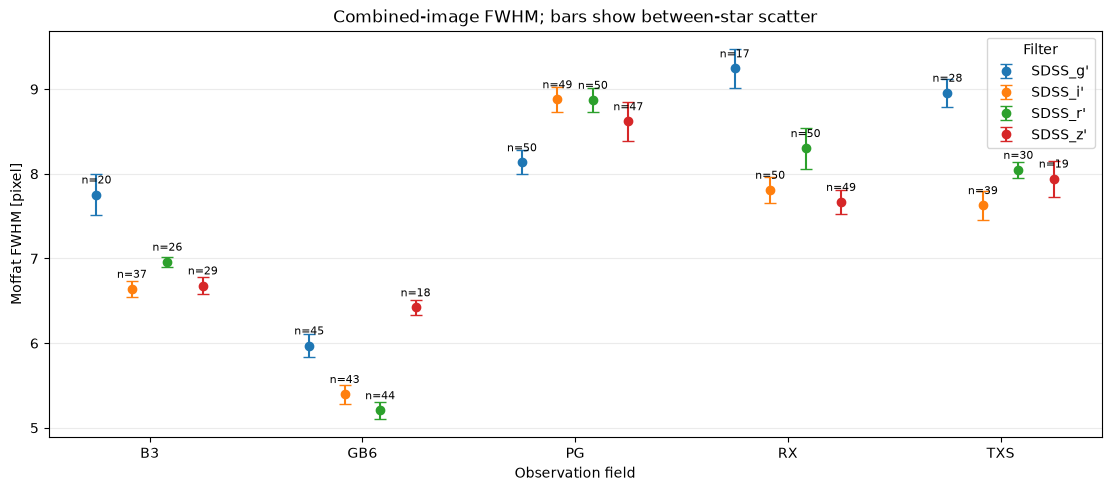

In [69]:
# Compare fields and filters; error bars show between-star scatter.
figure = fwhm_measurement.plot_fwhm()

# Photometry

## Standard Star Matching

### Load and check the standard star catalog metadata

In [23]:
# Locate the compiled standard-star catalog.
catalog_path: Path = Path(
    "/Users/yong/Desktop/Research/Photozpy/"
    "Compiled_Standard_Stars/Smith_Southern_Sky.h5"
)

# Initialize the catalog reader and load its metadata.
standard_star = StandardStarCatalog(
    catalog_path=catalog_path,
)

standard_star.print_metadata()

╒═════════════════╤═════════════════════════════════════════════════════════════════════════════════════╕
│ Field           │ Value                                                                               │
╞═════════════════╪═════════════════════════════════════════════════════════════════════════════════════╡
│ catalog_path    │ /Users/yong/Desktop/Research/Photozpy/Compiled_Standard_Stars/Smith_Southern_Sky.h5 │
├─────────────────┼─────────────────────────────────────────────────────────────────────────────────────┤
│ table_node_path │ /smith/southern/std                                                                 │
├─────────────────┼─────────────────────────────────────────────────────────────────────────────────────┤
│ table_node_name │ std                                                                                 │
├─────────────────┼─────────────────────────────────────────────────────────────────────────────────────┤
│ table_title     │ Standard Stars            

### Use one master standard star image to match the standard stars in FOV

In [24]:
# Get one Master Light from the standard field using the last telescope filter.

standard_star_path = analysis_images[0].files_filtered(
    imtype="Master Light",
    field=standard_star_field.field_name,
    filter=standard_star_field.telescope.filters()[-1],
    include_path=True,
)[0]

print(f"The selected master standard star for matching is {Path(standard_star_path).name}")

The selected master standard star for matching is Master_PG_SDSS_z'.fits


In [25]:
# Query catalog stars inside the standard-field image.
# Require a distance greater than 100 pixels from the image edges.
# Require catalog magnitudes <= 23 in every automatically matched filter.
# Resolve magnitude and uncertainty columns through the field's Telescope.
# Create one SourceInfo per star and attach its AB reference magnitudes.
standard_sources: Sources = standard_star.find_standard_sources(
    fits_path=standard_star_path,
    observation_field=standard_star_field,
    magnitude_system="AB",
    edge_margin_pix=100.0,
    mag_limit=23.0,
)

In [26]:
# Show the number of matched standard-star candidates.
print(f"Matched standard stars: {len(standard_sources)}")

# Display all matched stars and their catalog measurements in one table.
standard_star.matched_stars

Matched standard stars: 15


,id_name,ra,ra_err,dec,dec_err,SDSS_up,SDSS_gp,SDSS_rp,SDSS_ip,SDSS_zp,SDSS_up_err,SDSS_gp_err,SDSS_rp_err,SDSS_ip_err,SDSS_zp_err,ipix,bucket,x_pix,y_pix,edge_dist_pix
0,ugriz~J163533.3+094620,248.888748,NaN,9.772388,NaN,15.956000,13.475000,12.612,12.326,12.168,0.002646,0.001512,0.001134,0.001512,0.001890,2022083,1316,1088.884766,660.435976,660.435976
1,ugriz~J163537.2+094615,248.905289,NaN,9.771000,NaN,16.386999,13.761000,12.851,12.542,12.367,0.007181,0.001134,0.001134,0.001134,0.001890,2022083,1316,1261.912583,648.706835,648.706835
2,ugriz~J163545.0+094924,248.937836,NaN,9.823500,NaN,15.169000,13.500000,12.855,12.608,12.485,0.002646,0.000756,0.001134,0.001512,0.001512,2022083,1316,1591.873386,1210.657840,455.126614
4,ugriz~J163536.7+094940,248.902954,NaN,9.827888,NaN,15.774000,14.176000,13.487,13.169,13.001,0.003024,0.001134,0.001134,0.001890,0.001890,2022083,1316,1227.098325,1250.781105,796.218895
5,ugriz~J163540.0+094641,248.917038,NaN,9.778194,NaN,15.066000,13.910000,13.552,13.441,13.416,0.003402,0.001512,0.001134,0.001512,0.001512,2022083,1316,1383.194637,727.045890,663.805363
6,ugriz~J163532.3+095030,248.884750,NaN,9.841778,NaN,15.395000,14.065000,13.554,13.369,13.290,0.002268,0.001134,0.001134,0.001134,0.001890,2022083,1316,1034.727350,1394.597314,652.402686
9,ugriz~J163524.0+094749,248.850082,NaN,9.797194,NaN,14.073000,14.202000,14.588,14.912,15.167,0.002268,0.001134,0.000378,0.003402,0.006047,2022083,1316,680.924819,916.312953,680.924819
10,ugriz~J163537.0+095135,248.904205,NaN,9.859777,NaN,16.743999,15.310000,14.794,14.620,14.557,0.005292,0.002646,0.002268,0.001890,0.003024,2022083,1316,1234.429704,1588.680473,458.319527
11,ugriz~J163536.9+095130,248.904007,NaN,9.858583,NaN,16.785000,15.319000,14.802,14.622,14.557,0.004919,0.002268,0.002646,0.002646,0.003402,2022083,1316,1232.651117,1575.999141,471.000859
12,ugriz~J163551.6+095010,248.964996,NaN,9.836278,NaN,17.368999,15.582000,14.919,14.656,14.550,0.012075,0.001134,0.002268,0.003024,0.003780,2022083,1316,1872.794806,1350.981220,174.205194


### Generate the region files (aperture and annulus)

In [74]:
# Find the standard field's Master Lights across all available filters.
# Centroid each image independently and use its own header FWHM.
standard_regions: PhotometryRegionCollection = PhotometryRegions.generate_regions(
    image_collection=analysis_images,
    sources=standard_sources,
    root=analysis_dir,
    aperture_scaling=3.0,
    inner_annulus_scaling=5.0,
    outer_annulus_scaling=8.0,
    box_size=19,
    overwrite=True,
)

# Report the number of image/group entries prepared for review.
print(f"Standard-field review entries: {len(standard_regions)}")

Standard-field review entries: 4


In [75]:
import pandas as pd


# Display all stars, centroid outcomes, fallback reasons and region geometry.
pd.DataFrame(standard_regions.records)

,source_id,field_name,source_role,aperture_path,background_path,initial_x,initial_y,auto_x,auto_y,x,...,aperture_radius,inner_radius,outer_radius,generated_radii,accepted,reviewed,aperture_valid_fraction,annulus_valid_fraction,image_path,filter_name
0,ugriz~J163533.3+094620,PG,standard,photometry/regions/PG_standards/SDSS_g'_apertu...,photometry/regions/PG_standards/SDSS_g'_backgr...,1088.735288,660.514676,1089.255154,659.989614,1089.255154,...,24.403355,40.672258,65.075613,"[24.403354852537483, 40.672258087562476, 65.07...",True,False,1.0,1.0,Master_PG_SDSS_g'.fits,SDSS_g'
1,ugriz~J163537.2+094615,PG,standard,photometry/regions/PG_standards/SDSS_g'_apertu...,photometry/regions/PG_standards/SDSS_g'_backgr...,1261.607485,648.792966,1261.226407,649.838536,1261.226407,...,24.403355,40.672258,65.075613,"[24.403354852537483, 40.672258087562476, 65.07...",True,False,1.0,1.0,Master_PG_SDSS_g'.fits,SDSS_g'
2,ugriz~J163545.0+094924,PG,standard,photometry/regions/PG_standards/SDSS_g'_apertu...,photometry/regions/PG_standards/SDSS_g'_backgr...,1591.539783,1210.733577,1591.424604,1210.573465,1591.424604,...,24.403355,40.672258,65.075613,"[24.403354852537483, 40.672258087562476, 65.07...",True,False,1.0,1.0,Master_PG_SDSS_g'.fits,SDSS_g'
3,ugriz~J163536.7+094940,PG,standard,photometry/regions/PG_standards/SDSS_g'_apertu...,photometry/regions/PG_standards/SDSS_g'_backgr...,1226.823827,1250.867806,1226.873003,1250.070987,1226.873003,...,24.403355,40.672258,65.075613,"[24.403354852537483, 40.672258087562476, 65.07...",True,False,1.0,1.0,Master_PG_SDSS_g'.fits,SDSS_g'
4,ugriz~J163540.0+094641,PG,standard,photometry/regions/PG_standards/SDSS_g'_apertu...,photometry/regions/PG_standards/SDSS_g'_backgr...,1382.884663,727.125324,1382.795828,727.026375,1382.795828,...,24.403355,40.672258,65.075613,"[24.403354852537483, 40.672258087562476, 65.07...",True,False,1.0,1.0,Master_PG_SDSS_g'.fits,SDSS_g'
5,ugriz~J163532.3+095030,PG,standard,photometry/regions/PG_standards/SDSS_g'_apertu...,photometry/regions/PG_standards/SDSS_g'_backgr...,1034.356717,1394.681010,1034.836474,1393.726886,1034.836474,...,24.403355,40.672258,65.075613,"[24.403354852537483, 40.672258087562476, 65.07...",True,False,1.0,1.0,Master_PG_SDSS_g'.fits,SDSS_g'
6,ugriz~J163524.0+094749,PG,standard,photometry/regions/PG_standards/SDSS_g'_apertu...,photometry/regions/PG_standards/SDSS_g'_backgr...,680.631133,916.346555,679.398611,915.753311,679.398611,...,24.403355,40.672258,65.075613,"[24.403354852537483, 40.672258087562476, 65.07...",True,False,1.0,1.0,Master_PG_SDSS_g'.fits,SDSS_g'
7,ugriz~J163537.0+095135,PG,standard,photometry/regions/PG_standards/SDSS_g'_apertu...,photometry/regions/PG_standards/SDSS_g'_backgr...,1234.085964,1588.789110,1234.034688,1588.984247,1234.034688,...,24.403355,40.672258,65.075613,"[24.403354852537483, 40.672258087562476, 65.07...",True,False,1.0,1.0,Master_PG_SDSS_g'.fits,SDSS_g'
8,ugriz~J163536.9+095130,PG,standard,photometry/regions/PG_standards/SDSS_g'_apertu...,photometry/regions/PG_standards/SDSS_g'_backgr...,1232.232700,1576.109624,1233.387575,1582.512277,1233.387575,...,24.403355,40.672258,65.075613,"[24.403354852537483, 40.672258087562476, 65.07...",True,False,1.0,1.0,Master_PG_SDSS_g'.fits,SDSS_g'
9,ugriz~J163551.6+095010,PG,standard,photometry/regions/PG_standards/SDSS_g'_apertu...,photometry/regions/PG_standards/SDSS_g'_backgr...,1872.497431,1351.052826,1872.700323,1350.472026,1872.700323,...,24.403355,40.672258,65.075613,"[24.403354852537483, 40.672258087562476, 65.07...",True,False,1.0,1.0,Master_PG_SDSS_g'.fits,SDSS_g'


In [76]:
# Load the image with editable apertures/annuli and fixed initial-position crosses.
# Click Save & Next to validate and save the current edits.
standard_regions.review(sync_deletions=True)

In [19]:
# reload regions
# standard_regions = PhotometryRegions.load_regions(
#     image_collection=analysis_images,
#     sources=standard_sources,
#     root=analysis_dir,
# )

## Generate Region File for Science Targets

In [77]:
# Generate regions for all science targets across their available filters.
science_regions = PhotometryRegions.generate_regions(
    image_collection=analysis_images,
    sources=sources,
    root=analysis_dir,
    aperture_scaling=3.0,
    inner_annulus_scaling=5.0,
    outer_annulus_scaling=8.0,
    box_size=25,
    overwrite=True,
)

In [79]:
# Review and save the generated regions in one DS9 session.
science_regions.review()

In [20]:
# # reload regions
# science_regions = PhotometryRegions.load_regions(
#     image_collection=analysis_images,
#     sources=sources,
#     root=analysis_dir,
# )

## Perform Photometry

In [27]:
# # reload regions if needed

# Read the saved standard-star regions for every filter.
# Preserve all manual positions, radii and review decisions.
standard_regions = PhotometryRegions.load_regions(
    image_collection=analysis_images,
    sources=standard_sources,
    root=analysis_dir,
)


# # Read the saved science-target regions without regenerating them.
science_regions = PhotometryRegions.load_regions(
    image_collection=analysis_images,
    sources=sources,
    root=analysis_dir,
)


In [28]:
# Use the existing analysis image selection.
photometry = Photometry(
    image_collection=analysis_images,
)


In [29]:
# Measure all reviewed standards and science targets in one operation.
# Preserve existing reference results and update the original instrumental slots.
from photozpy.photometry import LocalBackgroundOptions

photometry_table = photometry.run_photometry(
    sources=(standard_sources, sources),
    regions=(standard_regions, science_regions),
    bkg_clip_sigma=3.0,
    src_detection_sigma=3.0,
    background_options=LocalBackgroundOptions(),
    verbose=False,
)

# Display all source/filter measurements in one table.
#photometry_table

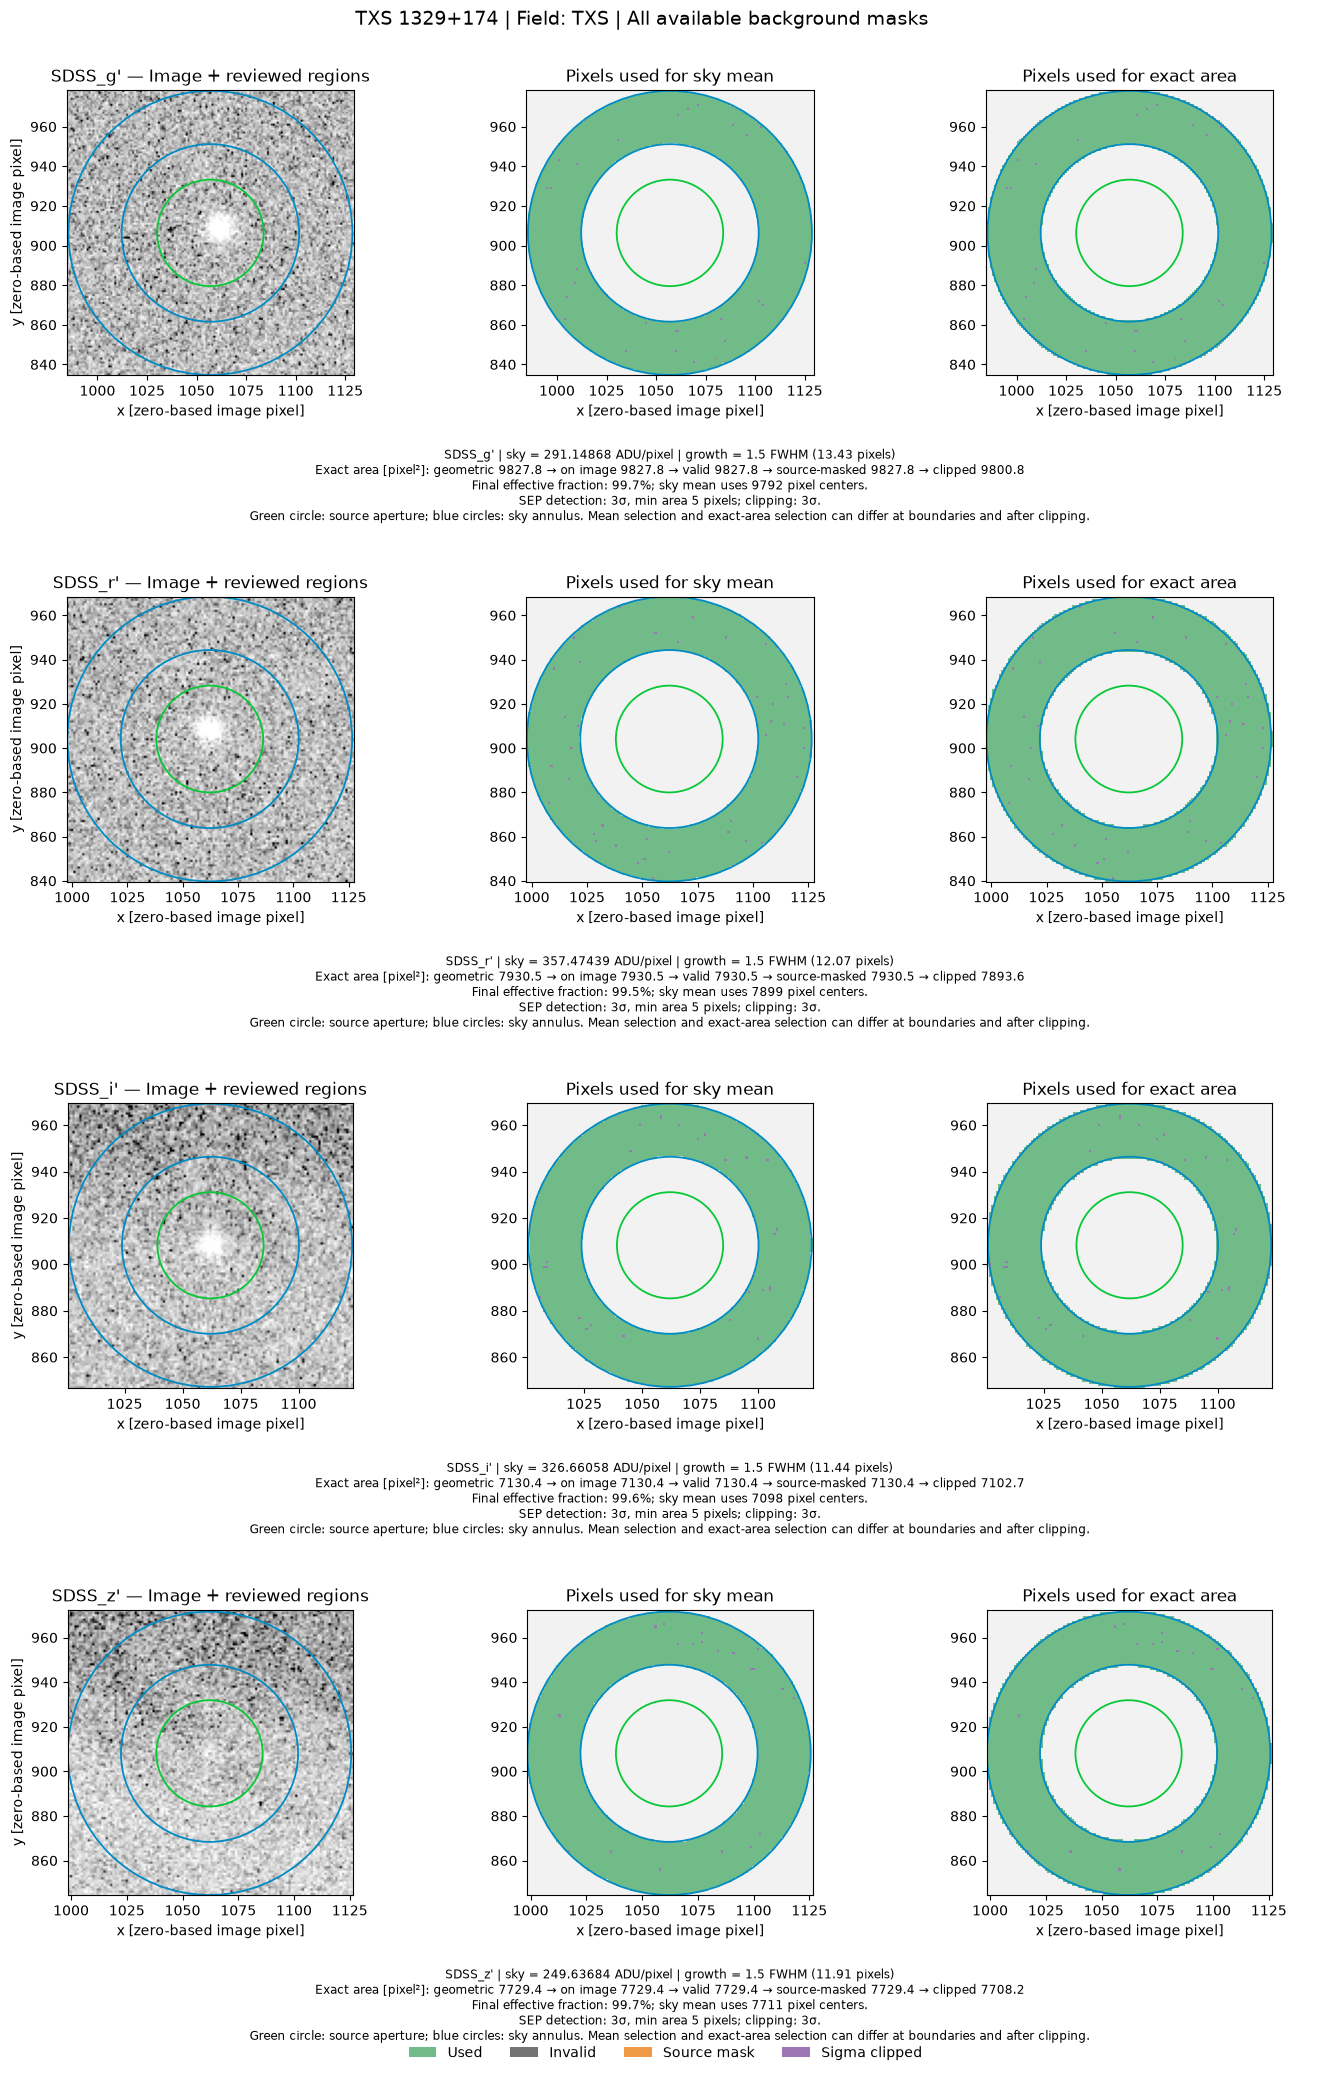

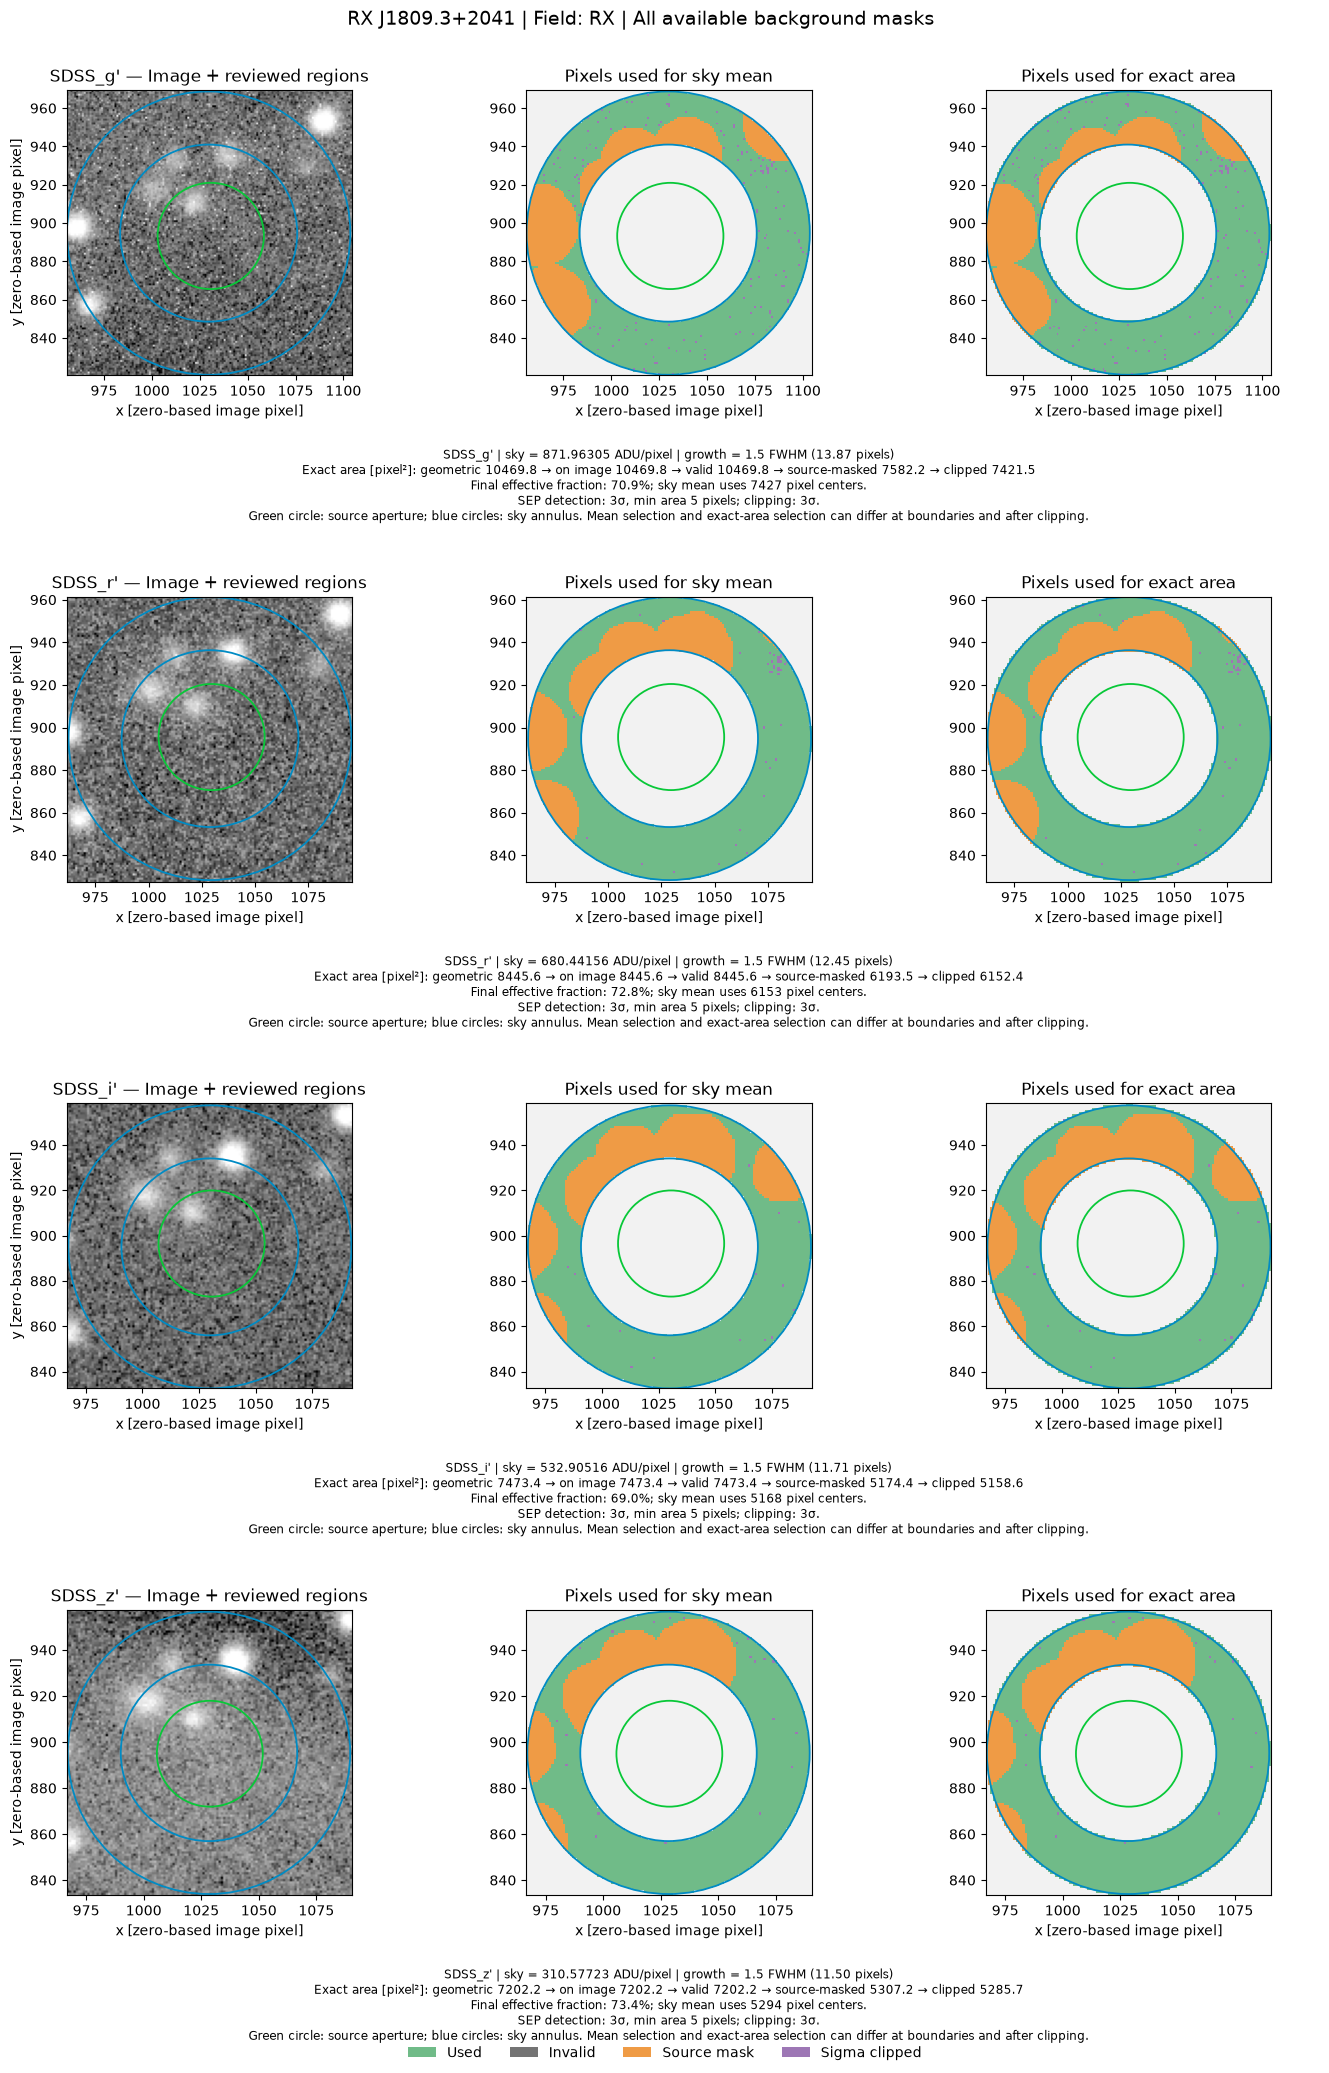

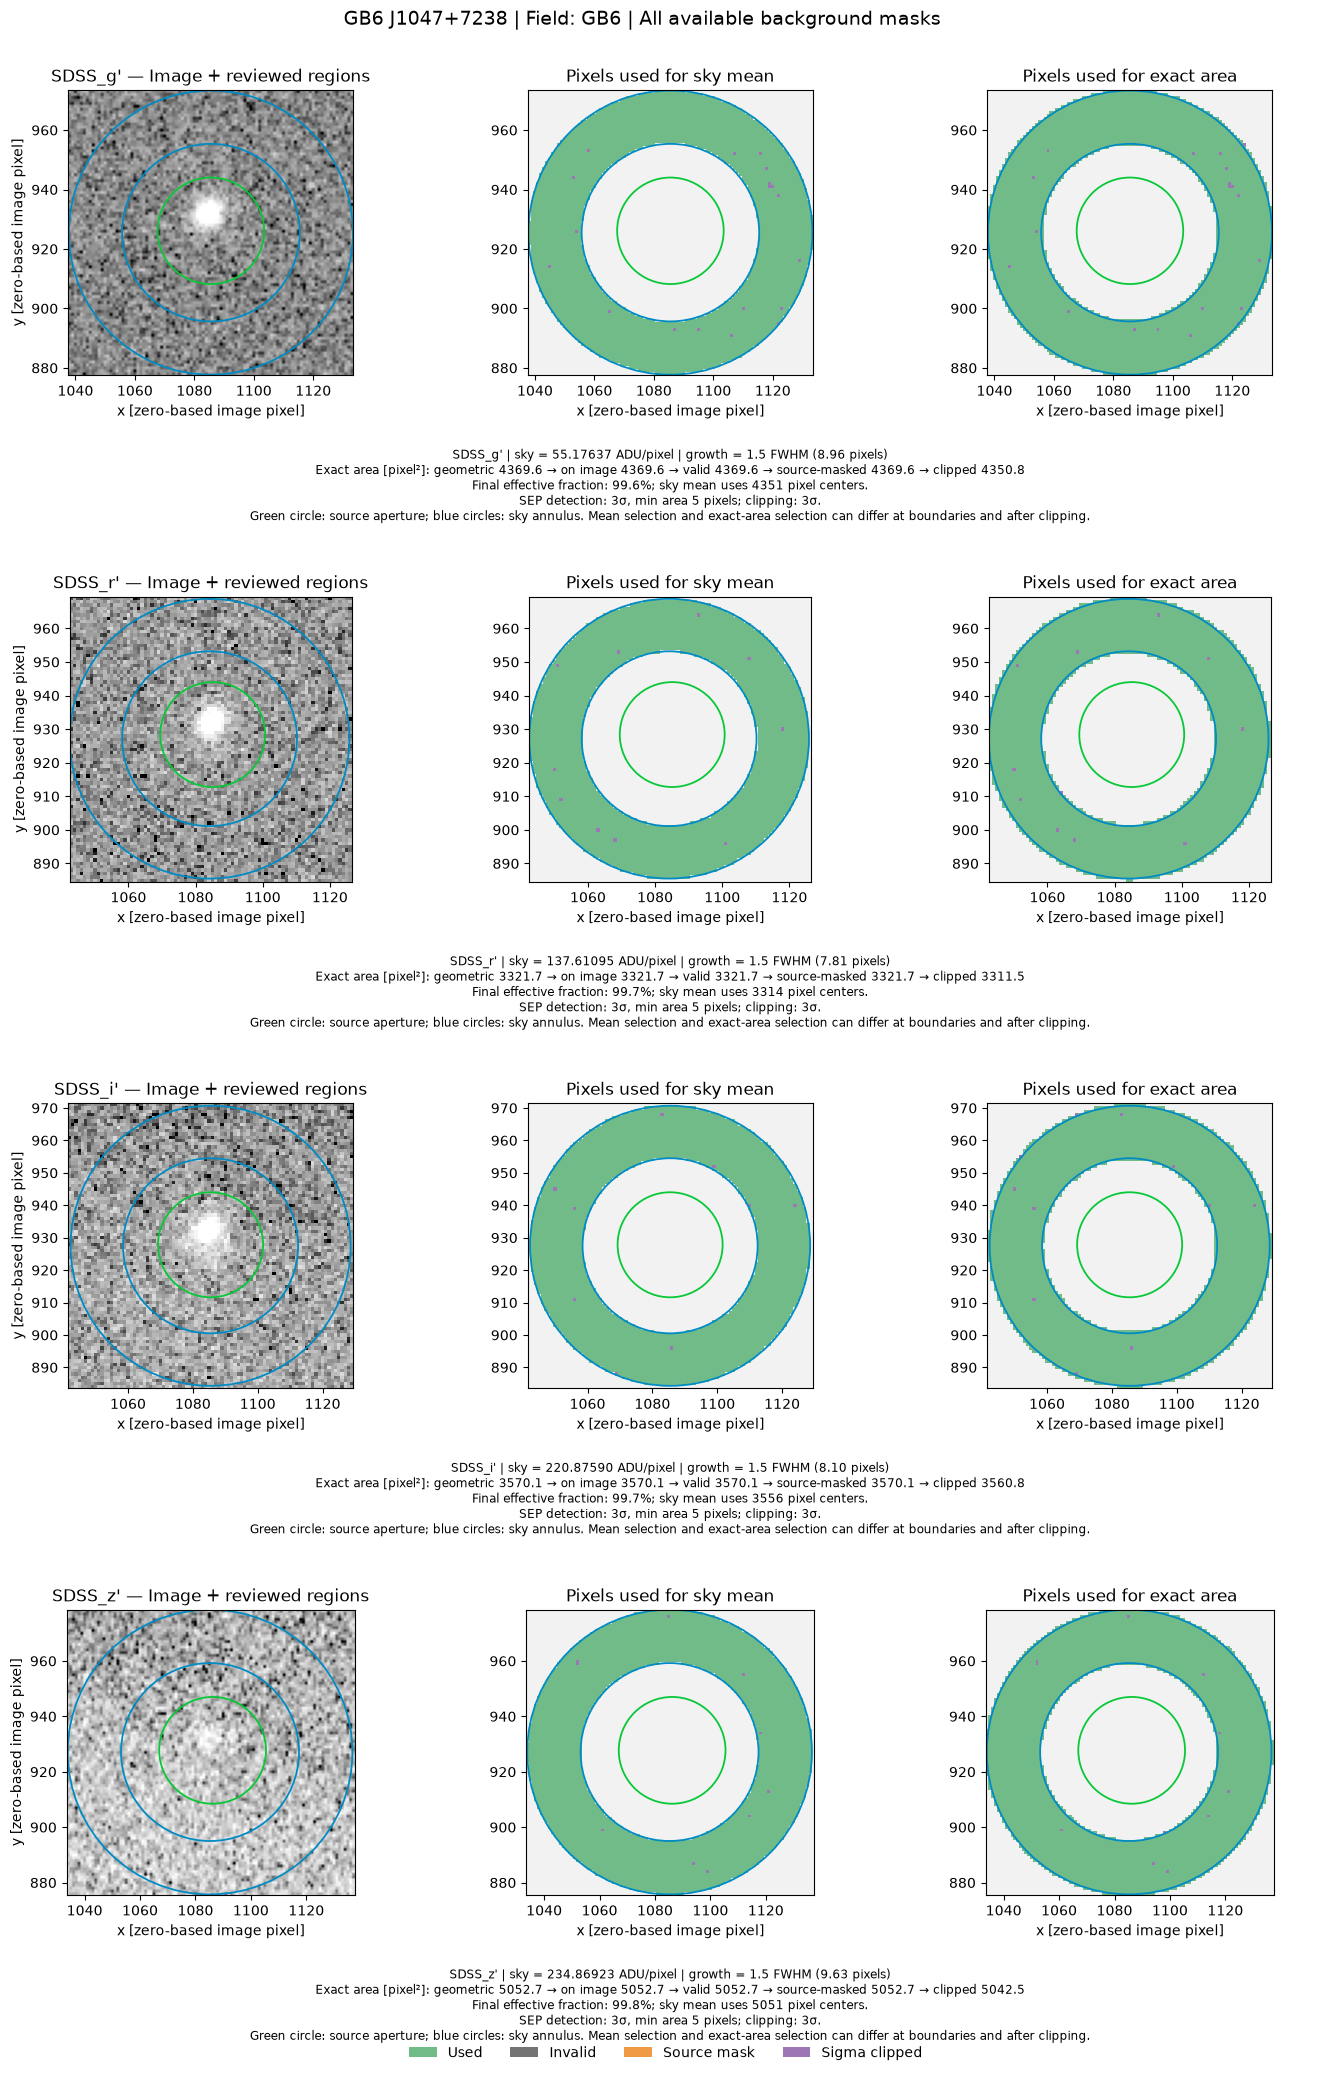

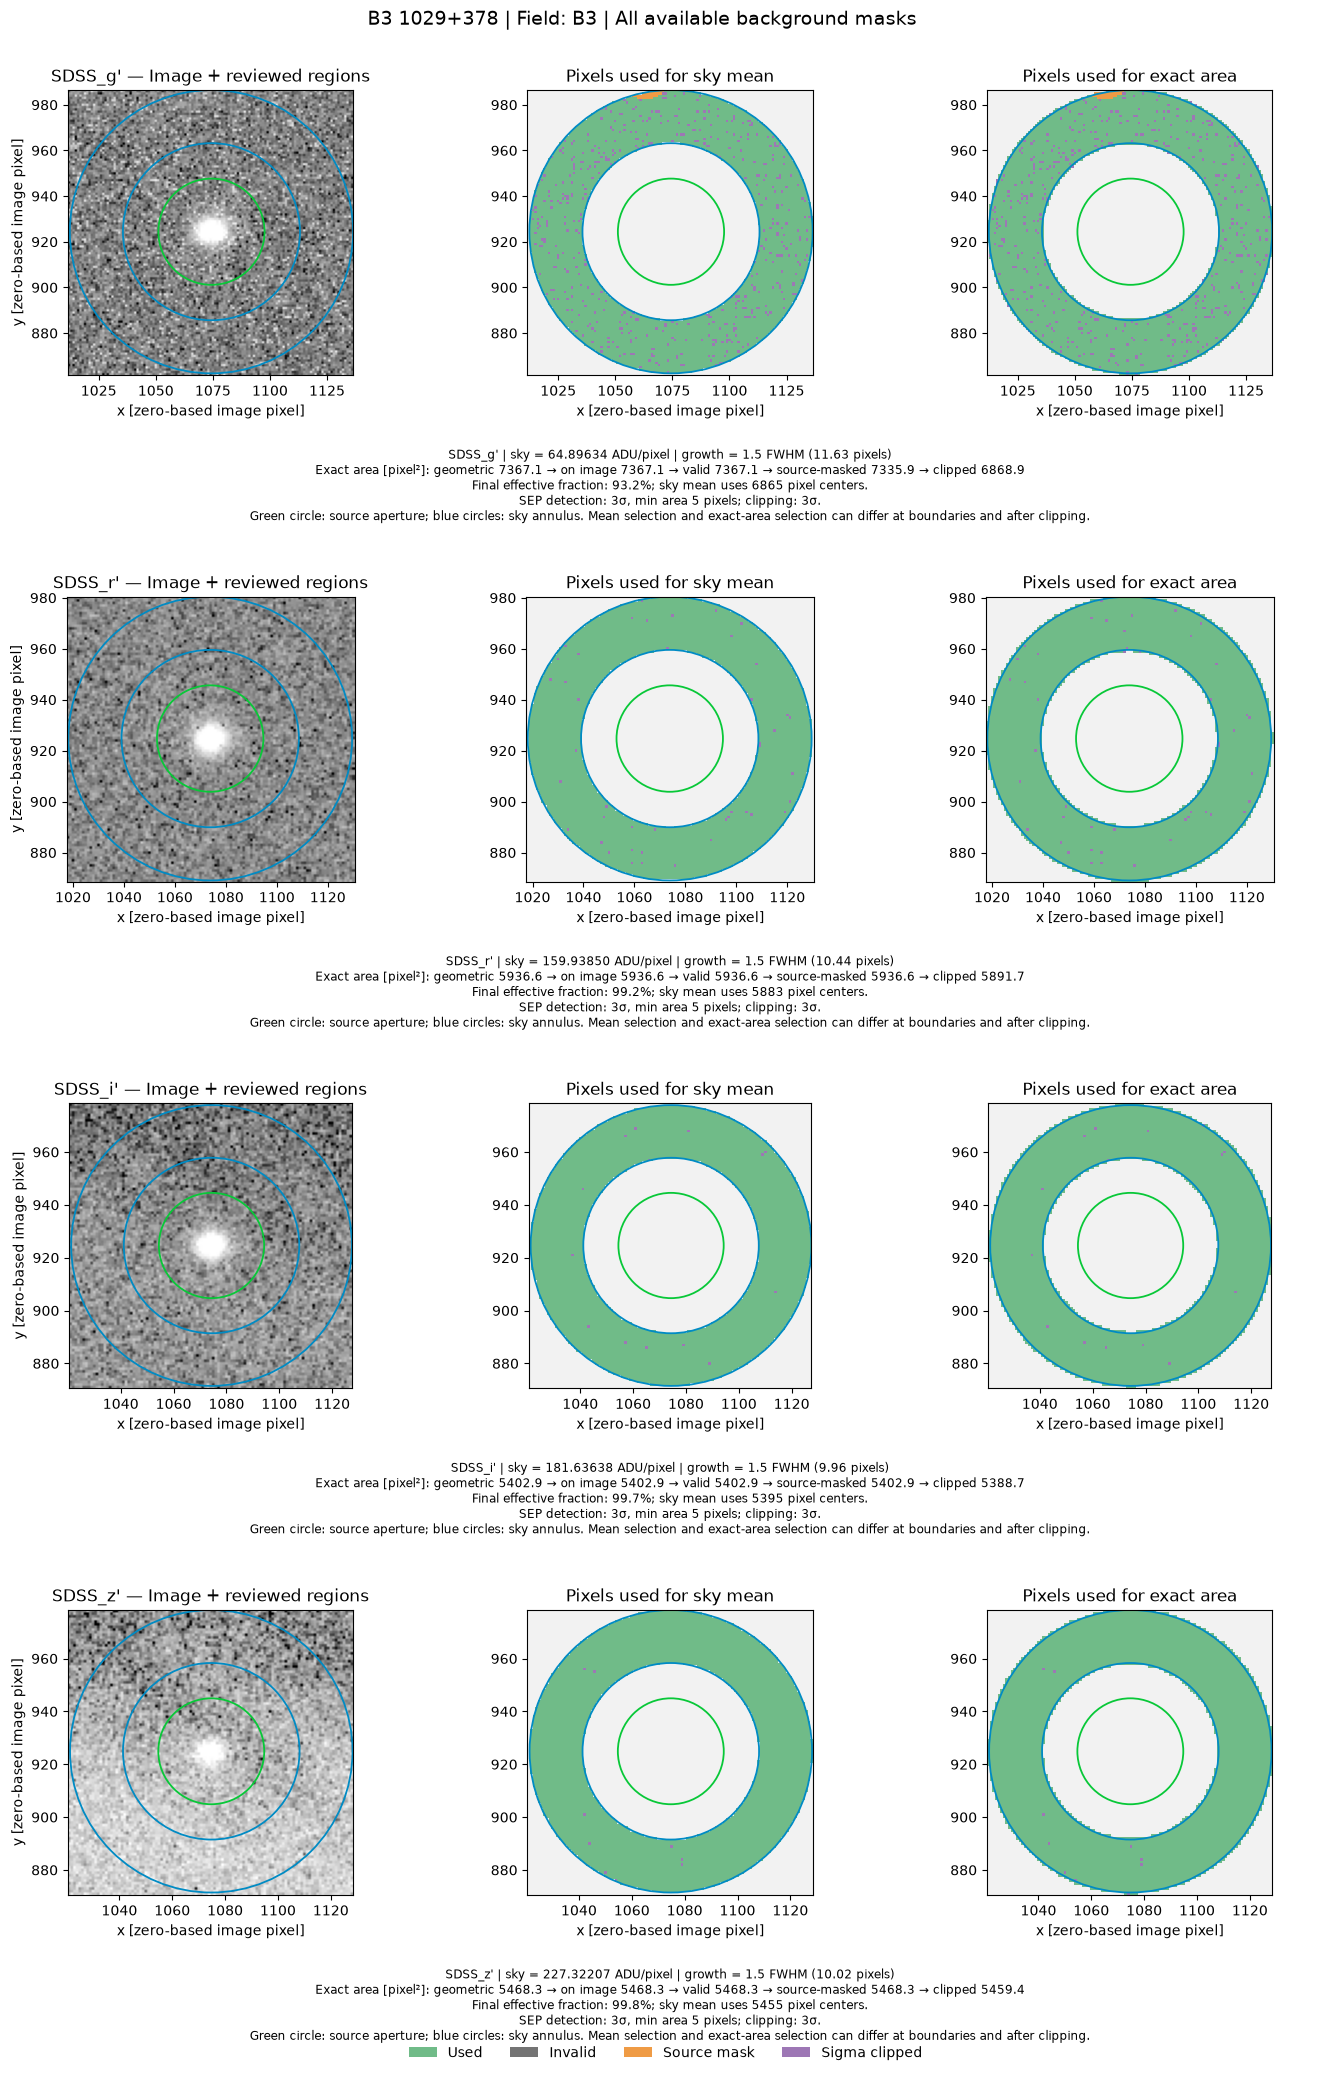

In [30]:
import matplotlib.pyplot as plt

figures = photometry.plot_background_diagnostics(sources)
plt.show()

## Compute Zero Points and Calibrate Magnitudes

In [31]:
# Calculate per-filter zero points from the standard-star measurements.
# Use the original single-pass z-score clipping and unweighted average.
zero_point_table = standard_sources.calculate_zero_points(
    sigma=3.0,
    min_significance=3.0,
)

# Show the average zero point, retained scatter, and sample counts.
# Numerical zero_point and scatter values are in magnitudes.
zero_point_table

,filter,zero_point,scatter,n_candidates,n_used,n_clipped,magnitude_system
0,SDSS_u',NaN,NaN,0,0,0,AB
1,SDSS_g',28.214328,0.021880,12,12,0,AB
2,SDSS_r',27.973922,0.023326,12,12,0,AB
3,SDSS_i',27.396068,0.030711,12,12,0,AB
4,SDSS_z',26.296166,0.104462,12,12,0,AB


In [32]:
# Retrieve individual standard-star zero points in every filter.
# Include whether each measurement was used and the exclusion reason.
standard_zero_point_table = standard_sources.zero_point_details

# Display the complete DataFrame for inspection.
standard_zero_point_table

,source_id,field,filter,reference_magnitude,instrumental_magnitude,significance,zero_point,used,reason
0,ugriz~J163533.3+094620,PG,SDSS_u',15.956000,NaN,NaN,NaN,False,missing_magnitude
1,ugriz~J163533.3+094620,PG,SDSS_g',13.475000,-14.752144,1331.152479,28.227144,True,retained
2,ugriz~J163533.3+094620,PG,SDSS_r',12.612000,-15.351654,1901.230070,27.963654,True,retained
3,ugriz~J163533.3+094620,PG,SDSS_i',12.326000,-15.056465,1631.055391,27.382465,True,retained
4,ugriz~J163533.3+094620,PG,SDSS_z',12.168000,-14.087940,929.695625,26.255940,True,retained
...,...,...,...,...,...,...,...,...,...
70,ugriz~J163543.8+094909,PG,SDSS_u',17.287001,NaN,NaN,NaN,False,missing_magnitude
71,ugriz~J163543.8+094909,PG,SDSS_g',16.097000,-12.127209,143.636325,28.224209,True,retained
72,ugriz~J163543.8+094909,PG,SDSS_r',15.631000,-12.351787,153.304902,27.982787,True,retained
73,ugriz~J163543.8+094909,PG,SDSS_i',15.477000,-12.001644,123.611588,27.478644,True,retained


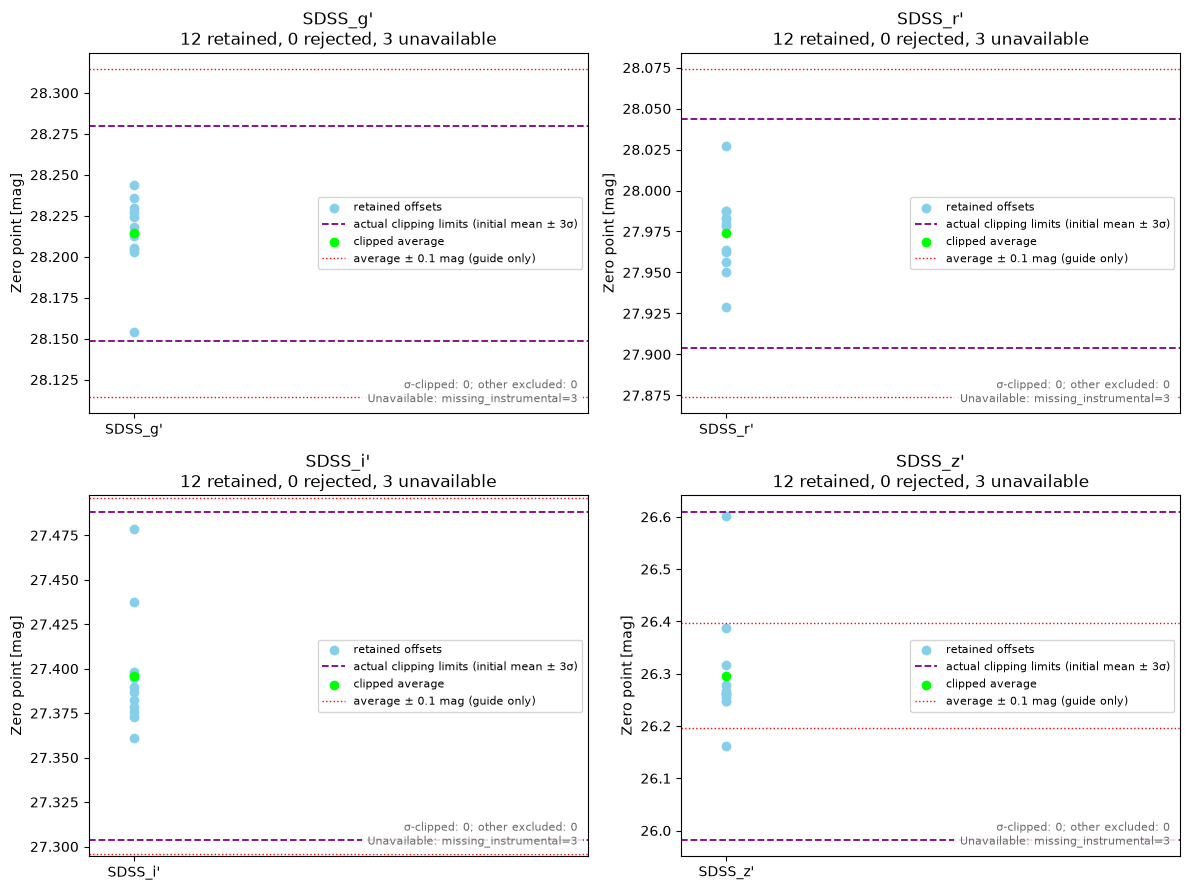

In [33]:
# Plot individual standard-star zero points and the retained average.
# Red lines mark average +/- 0.1 mag as visual guides.
zero_point_figure = standard_sources.plot_zero_point_statistics()

In [34]:
# Apply the inspected standard-star zero points to all science targets.
# Preserve instrumental errors, significance, and upper-limit flags.
calibrated_table = sources.calibrate_targets(
    standard_sources=standard_sources,
)

# Show calibrated results for every science source and filter.
#calibrated_table

In [35]:
# Display one compact filter/magnitude/error/significance summary per source.
sources.show_magnitudes(kind="calibrated")

TXS 1329+174
RA / Dec (ICRS): 13:31:33.440	+17:12:50.600
Field: TXS
Magnitude system: AB
╒══════════╤═══════════════════╤═══════════════╤════════════════╕
│ Filter   │ Magnitude (mag)   │ Error (mag)   │ Significance   │
╞══════════╪═══════════════════╪═══════════════╪════════════════╡
│ SDSS_u'  │ --                │ --            │ --             │
├──────────┼───────────────────┼───────────────┼────────────────┤
│ SDSS_g'  │ 19.7076           │ 0.0844        │ 12.86          │
├──────────┼───────────────────┼───────────────┼────────────────┤
│ SDSS_r'  │ 19.2180           │ 0.0865        │ 12.55          │
├──────────┼───────────────────┼───────────────┼────────────────┤
│ SDSS_i'  │ 18.5314           │ 0.0770        │ 14.10          │
├──────────┼───────────────────┼───────────────┼────────────────┤
│ SDSS_z'  │ 18.8222           │ UL (-99)      │ 2.63           │
╘══════════╧═══════════════════╧═══════════════╧════════════════╛

RX J1809.3+2041
RA / Dec (ICRS): 18:09:25.450	+20:41

In [37]:
# Export numerical results after photometry and calibration are complete.
# This only saves existing results; it does not rerun the analysis.

results_dir = analysis_dir / "photometry" / "results"
results_dir.mkdir(parents=True, exist_ok=True)

tables = {
    "science_photometry.csv": calibrated_table,
    "zero_points.csv": standard_sources.zero_points,
    "standard_star_zero_point_details.csv": standard_sources.zero_point_details,
}

for filename, table in tables.items():
    output_path = results_dir / filename
    table.to_csv(
        output_path,
        index=False,
        na_rep="NaN",
        encoding="utf-8",
    )
    print(f"Saved: {output_path} ({len(table)} rows)")

Saved: analysis/photometry/results/science_photometry.csv (20 rows)
Saved: analysis/photometry/results/zero_points.csv (5 rows)
Saved: analysis/photometry/results/standard_star_zero_point_details.csv (75 rows)


In [39]:
import pandas as pd

saved_results = pd.read_csv(
    analysis_dir / "photometry" / "results" / "science_photometry.csv"
)
saved_results

,source_id,field,filter,instrumental_magnitude,zero_point,calibrated_magnitude,error,significance,is_upper_limit,magnitude_system,status
0,TXS 1329+174,TXS,SDSS_u',NaN,NaN,NaN,NaN,NaN,False,AB,missing_instrumental
1,TXS 1329+174,TXS,SDSS_g',-8.506739,28.214328,19.707590,0.084400,12.864211,False,AB,calibrated
2,TXS 1329+174,TXS,SDSS_r',-8.755948,27.973922,19.217974,0.086508,12.550761,False,AB,calibrated
3,TXS 1329+174,TXS,SDSS_i',-8.864661,27.396068,18.531407,0.077026,14.095729,False,AB,calibrated
4,TXS 1329+174,TXS,SDSS_z',-7.474005,26.296166,18.822160,-99.000000,2.632100,True,AB,upper_limit
5,RX J1809.3+2041,RX,SDSS_u',NaN,NaN,NaN,NaN,NaN,False,AB,missing_instrumental
6,RX J1809.3+2041,RX,SDSS_g',-9.729824,28.214328,18.484504,0.056158,19.333685,False,AB,calibrated
7,RX J1809.3+2041,RX,SDSS_r',-9.692701,27.973922,18.281221,0.046266,23.467386,False,AB,calibrated
8,RX J1809.3+2041,RX,SDSS_i',-9.593403,27.396068,17.802665,0.060572,17.924673,False,AB,calibrated
9,RX J1809.3+2041,RX,SDSS_z',-9.313349,26.296166,16.982816,0.036616,29.651843,False,AB,calibrated


In [36]:
sources.show_magnitudes(
    kind="calibrated",
    format="google_sheets",
)

In [89]:
# Display instrumental measurements for all sources.
sources.show_magnitudes(kind="instrumental")


TXS 1329+174
Field: TXS
Magnitude system: instrumental
╒══════════╤═══════════════════╤═══════════════╤════════════════╕
│ Filter   │ Magnitude (mag)   │ Error (mag)   │ Significance   │
╞══════════╪═══════════════════╪═══════════════╪════════════════╡
│ SDSS_u'  │ --                │ --            │ --             │
├──────────┼───────────────────┼───────────────┼────────────────┤
│ SDSS_g'  │ -8.5067           │ 0.0844        │ 12.86          │
├──────────┼───────────────────┼───────────────┼────────────────┤
│ SDSS_r'  │ -8.7559           │ 0.0865        │ 12.55          │
├──────────┼───────────────────┼───────────────┼────────────────┤
│ SDSS_i'  │ -8.8647           │ 0.0770        │ 14.10          │
├──────────┼───────────────────┼───────────────┼────────────────┤
│ SDSS_z'  │ -7.4740           │ UL (-99)      │ 2.63           │
╘══════════╧═══════════════════╧═══════════════╧════════════════╛

RX J1809.3+2041
Field: RX
Magnitude system: instrumental
╒══════════╤═════════════════

In [90]:
# Display catalog reference magnitudes for all standard stars.
standard_sources.show_magnitudes(kind="reference")

ugriz~J163533.3+094620
Field: PG
Magnitude system: AB
╒══════════╤═══════════════════╤═══════════════╤════════════════╕
│ Filter   │ Magnitude (mag)   │ Error (mag)   │ Significance   │
╞══════════╪═══════════════════╪═══════════════╪════════════════╡
│ SDSS_u'  │ 15.9560           │ 0.0026        │ --             │
├──────────┼───────────────────┼───────────────┼────────────────┤
│ SDSS_g'  │ 13.4750           │ 0.0015        │ --             │
├──────────┼───────────────────┼───────────────┼────────────────┤
│ SDSS_r'  │ 12.6120           │ 0.0011        │ --             │
├──────────┼───────────────────┼───────────────┼────────────────┤
│ SDSS_i'  │ 12.3260           │ 0.0015        │ --             │
├──────────┼───────────────────┼───────────────┼────────────────┤
│ SDSS_z'  │ 12.1680           │ 0.0019        │ --             │
╘══════════╧═══════════════════╧═══════════════╧════════════════╛

ugriz~J163537.2+094615
Field: PG
Magnitude system: AB
╒══════════╤═══════════════════╤═